<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [orchid](https://github.com/Gokaran-Shukla/orchid) · MIT License — any reuse must keep this copyright notice and credit the author.

# ORCHID tutorial 09: 3D device KMC with concurrent excitons

**Goals.** Run the full 3D device KMC (electrodes, injection, Coulomb and image charges, multilayer
stack), then the v0.4 concurrent charge + exciton engine.

### Theory
Holes and electrons hop with MA rates on the HOMO/LUMO energies of each layer. The electrodes inject and
extract over image-lowered barriers. The current follows the Ramo–Shockley theorem:
$J=\frac{e}{LA\,t}\sum_{\text{hops}}q\,\Delta z$. Electrostatics = mean-field sheets (1D Poisson Green's function)
+ exact screened Coulomb within $r_{coul}$ minus its sheet part.

**New in v0.4 (`CoupledDeviceKMC`).** When a hole and an electron meet, an exciton is created on that site
inside the same event loop. Charges and excitons share one clock: $R=R_c+R_x$, with two Fenwick trees.
Exciton–polaron quenching sees the *live* polaron positions. The v0.3 pipeline used a polaron
snapshot frozen from the mean density profile.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (5.4, 3.6), "axes.grid": True, "grid.alpha": 0.3})
import orchid
print("ORCHID", orchid.__version__)

ORCHID 0.4.0


J = 8.407e-01 A/m^2, gamma_b = 0.998


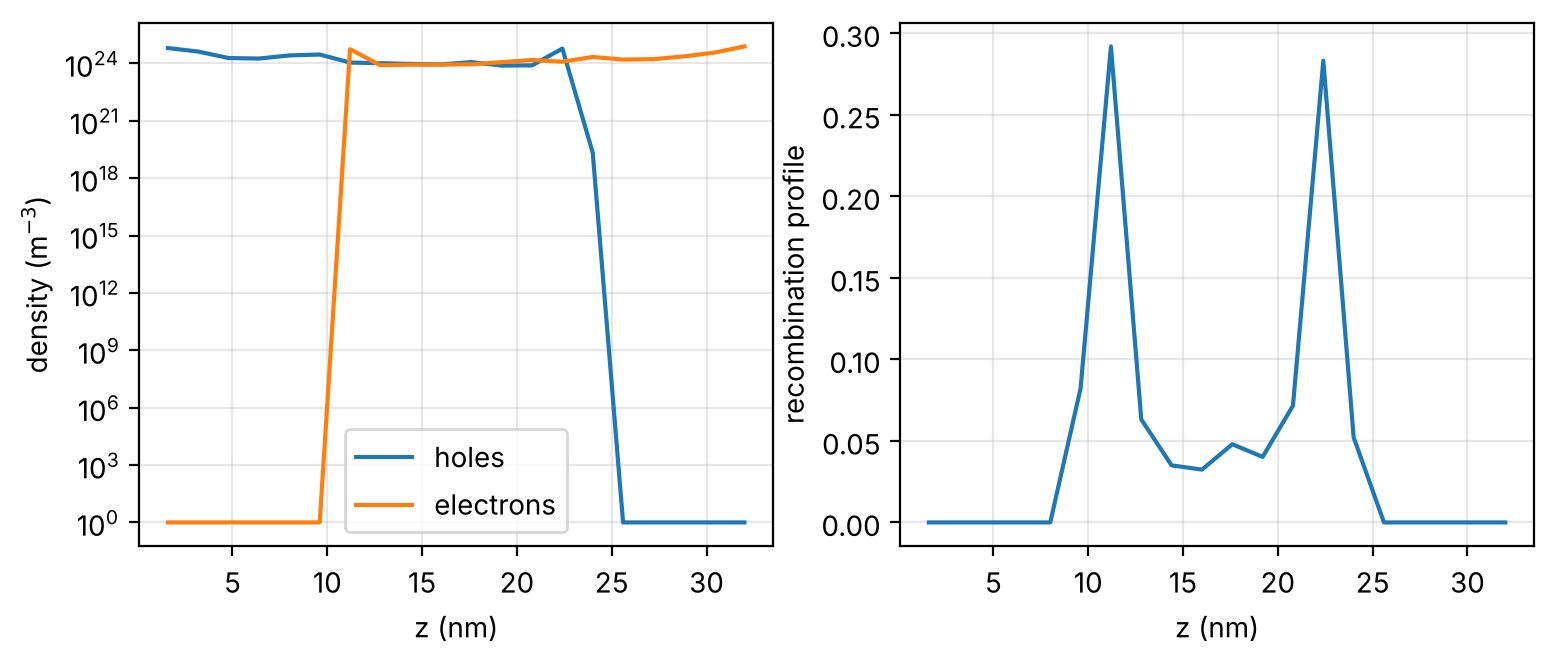

In [2]:
from orchid.device_kmc import DeviceKMC, Layer
STACK = [Layer(6, HOMO=-5.2, LUMO=-2.0, name="HTL"), Layer(8, HOMO=-5.4, LUMO=-2.7, name="EML"),
         Layer(6, HOMO=-6.0, LUMO=-2.8, name="ETL")]
d = DeviceKMC(STACK, Lx=12, Ly=12, W_anode=5.1, W_cathode=2.9, coulomb="full", seed=2)
r = d.run(6.0, n_eq=50000, n_meas=200000, mf_update=300)
print(f"J = {r['J']:.3e} A/m^2, gamma_b = {r['gamma_b']:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].semilogy(r["z"] * 1e9, r["p_z"] + 1, label="holes"); ax[0].semilogy(r["z"] * 1e9, r["n_z"] + 1, label="electrons")
ax[0].set_xlabel("z (nm)"); ax[0].set_ylabel(r"density (m$^{-3}$)"); ax[0].legend()
ax[1].plot(r["z"] * 1e9, r["rec_profile"]); ax[1].set_xlabel("z (nm)"); ax[1].set_ylabel("recombination profile");

Charges pile up at the HTL/EML and EML/ETL energy steps, and recombination is concentrated there.

In [3]:
from orchid.coupled_kmc import CoupledDeviceKMC
c = CoupledDeviceKMC(STACK, Lx=12, Ly=12, W_anode=5.1, W_cathode=2.9, coulomb="full", seed=2,
                     tau_r=1e-6, tau_nr=1e-5, k_TT0=1e8, k_q0=1e8, eta_out=0.2)
rc = c.run(6.0, n_eq=50000, n_meas=200000, mf_update=300)
x = rc["excitons"]
print(x)
print(f"EQE = {100*rc['EQE']:.2f} %  (radiative {rc['eta_rad']:.2f}, TPQ {rc['frac_TPQ']:.2f}, TTA {rc['frac_TTA']:.2f})")
print("bookkeeping:", x["formed"] + x["alive_start"] - (x["radiative"] + x["nonradiative"] + x["TPQ"]
                                                    + x["TTA"] + x["overflow"] + x["alive_end"]))

{'formed': 2672, 'radiative': 250, 'nonradiative': 24, 'TPQ': 2398, 'TTA': 0, 'overflow': 0, 'alive_start': 0, 'alive_end': 0}
EQE = 1.87 %  (radiative 0.09, TPQ 0.90, TTA 0.00)
bookkeeping: 0


**Exercise.** Turn quenching off (`k_q0=0, k_TT0=0`) and verify that `eta_rad` approaches $k_r/(k_r+k_{nr})=0.909$.

<details><summary>Solution</summary>

With $\tau_r=1\,\mu s$ and $\tau_{nr}=10\,\mu s$, $\eta=1/(1+0.1)=0.909$. Expect agreement within $\sqrt{\eta(1-\eta)/N}$ (V24: within 3σ).
</details>

## Quiz

Five questions on this section. Run the cell to see them, then grade yourself with
`quiz("09", answers="abcda")` (one letter per question). The same quiz runs in a terminal
with `orchid quiz 09`.

In [4]:
from orchid.tutorials import quiz
quiz("09")

Quiz 09: 3D device KMC with concurrent excitons

Q1. How does the device KMC compute the current with low noise?
    (a) From the Einstein relation
    (b) From the mean-field potential
    (c) By counting carriers that reach the electrodes
    (d) Ramo-Shockley: every hop contributes e q dz/(L A)

Q2. The image charge in the electrode makes a carrier near the contact
    (a) Higher in energy
    (b) Lower in energy, which lowers the injection barrier
    (c) Leave the device
    (d) Unchanged

Q3. Why are electrostatics split into a mean-field sheet part and an exact short-range part?
    (a) To remove image charges
    (b) To use the GPU
    (c) The sheet part is more accurate
    (d) Exact long-range Coulomb sums are too expensive. Sheets give the long-range part cheaply, and close pairs are treated exactly.

Q4. What changed for exciton-polaron quenching in v0.4 (CoupledDeviceKMC)?
    (a) TPQ is evaluated against the live polaron positions in the same event loop, not against a fro

In [5]:
# replace with your answers, e.g. "abcda"
# quiz("09", answers=".....")

<details><summary>Answer key</summary>

`dbdad`. Run `quiz("09", answers="dbdad")` to see the explanation for every question.
</details>

---
[Tutorial index](README.md) · ORCHID documentation · `orchid tutorials`